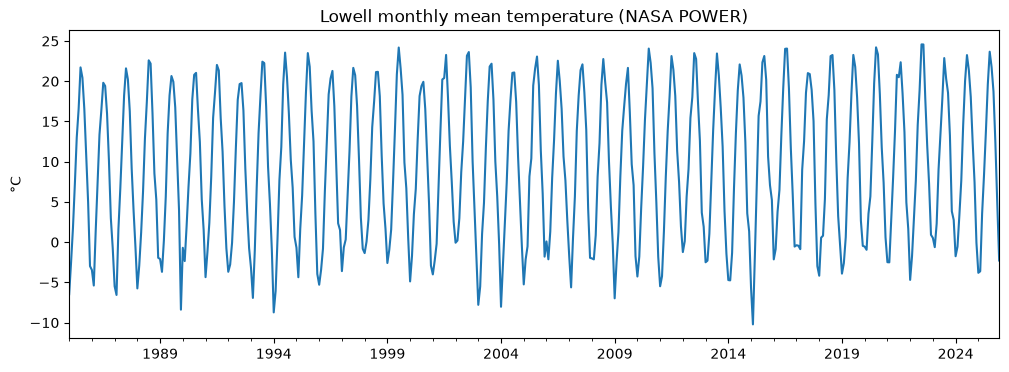

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

def get_power_monthly(lat, lon, variable="T2M", start=1985, end=2025):
    """Return a monthly time series for one NASA POWER variable at one location."""
    url = "https://power.larc.nasa.gov/api/temporal/monthly/point"
    params = {
        "parameters": variable,
        "community": "AG",
        "latitude": lat,
        "longitude": lon,
        "start": start,
        "end": end,
        "format": "JSON",
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()

    values = r.json()["properties"]["parameter"][variable]
    s = pd.Series(values)

    # Keys look like "198501" ... "198512", plus "198513" for the annual average. Drop the 13s.
    s = s[~s.index.str.endswith("13")]
    s.index = pd.to_datetime(s.index, format="%Y%m")

    # NASA POWER uses -999 for missing data
    s = s.replace(-999, float("nan"))
    s.name = variable
    return s.sort_index()


# Lowell, MA
temp = get_power_monthly(42.63, -71.32, "T2M")

temp.plot(figsize=(12, 4), title="Lowell monthly mean temperature (NASA POWER)")
plt.ylabel("°C")
plt.show()


Trend: increasing
p-value: 7.22e-14
Rate: 0.47 °C per decade


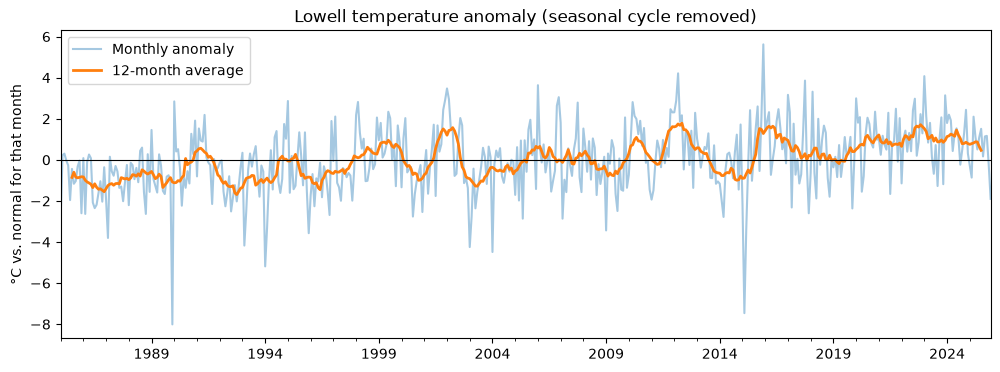

In [10]:
import pymannkendall as mk

# 1. Remove the seasonal cycle: subtract each calendar month's long-term average
monthly_avg = temp.groupby(temp.index.month).transform("mean")
anom = temp - monthly_avg

# 2. Test for a trend
result = mk.hamed_rao_modification_test(anom.dropna())
per_decade = result.slope * 120  # slope is per month; 120 months = 1 decade

print(f"Trend: {result.trend}")
print(f"p-value: {result.p:.2e}")
print(f"Rate: {per_decade:.2f} °C per decade")

# 3. Plot anomalies with a 12-month rolling average to show the slow change
ax = anom.plot(figsize=(12, 4), alpha=0.4, label="Monthly anomaly")
anom.rolling(12, center=True).mean().plot(ax=ax, linewidth=2, label="12-month average")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Lowell temperature anomaly (seasonal cycle removed)")
ax.set_ylabel("°C vs. normal for that month")
ax.legend()
plt.show()